# Understanding the Bias-Variance Tradeoff in Reinforcement Learning

## Introduction

Monte Carlo and temporal-difference (TD) learning solve the same prediction problem. Given a policy, we want to estimate the expected return from each state. The difference is in the target used to update those estimates.

Monte Carlo uses the complete sampled return. TD(0) uses one reward and the estimated value of the next state. This is usually described as a bias-variance tradeoff: Monte Carlo avoids bootstrap bias, but its targets can have more variance. TD uses an estimate of the remaining return, which can reduce variance at the cost of bias.

In this post, we'll make that distinction visible through a series of small experiments. We'll start with a Gridworld, separate the targets from the learning process, and then simplify the environment until independent reward noise is the only source of randomness. Finally, we'll compare n-step methods to see when a backup length between TD(0) and Monte Carlo works best.

All experiments in this notebook are prediction tasks. The policy stays fixed while the value estimates change.

## Monte Carlo and TD Targets

The state-value function is the expected return under a policy:

$$v_\pi(s)=\mathbb{E}_\pi[G_t\mid S_t=s].$$

For an episode ending at time $T$, the Monte Carlo target is:

$$Y_{\mathrm{MC}}=G_t=\sum_{k=0}^{T-t-1}\gamma^kR_{t+k+1}.$$

The TD(0) target is:

$$Y_{\mathrm{TD}}=R_{t+1}+\gamma\hat V(S_{t+1}).$$

For a terminal transition, the TD target is just the reward. Both methods move the current estimate toward their target:

$$\hat V(S_t)\leftarrow\hat V(S_t)+\alpha\left[Y-\hat V(S_t)\right].$$

The target is the quantity we move toward. It is different from both the current estimate and the TD error, $Y-\hat V(S_t)$. This distinction matters when we measure bias and variance.

## Measuring Bias and Variance

Suppose $X$ is an estimate of a quantity $v$. Its bias is the difference between its expected value and the truth:

$$\operatorname{Bias}(X)=\mathbb{E}[X]-v.$$

Bias is signed. An estimate that is too high has positive bias. Variance measures the spread around the estimate's own mean:

$$\operatorname{Var}(X)=\mathbb{E}\left[(X-\mathbb{E}[X])^2\right].$$

Mean squared error combines the two:

$$\operatorname{MSE}(X)=\operatorname{Bias}(X)^2+\operatorname{Var}(X).$$

An RMSE curve alone doesn't tell us how much error comes from bias and how much comes from variance. We'll plot the components separately.

There are two different random quantities we can examine. First, we can collect many update targets while keeping the value table fixed. Second, we can repeat the entire training process and collect the learned estimates after the same number of episodes. We'll do both.

First, we import the libraries and define the experiment settings. 

In [1]:
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


@dataclass
class Config:
    runs: int = 500
    episodes: int = 1000
    target_samples: int = 100_000
    alpha: float = 0.05
    gamma: float = 0.9
    horizon: int = 20
    seed: int = 42


config = Config()

# Record the early episodes and a few later training budgets.
early_episodes = np.arange(1, 11)
later_episodes = np.geomspace(1, config.episodes, 80).astype(int)
training_budgets = np.array([10, 30, 100, 300, config.episodes])

checkpoints = np.concatenate((early_episodes, later_episodes, training_budgets))
checkpoints = np.unique(checkpoints)

# Keep the image folder beside this notebook.
figure_directory = Path("figures")
figure_directory.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.figsize": (9, 4),
})

COLORS = {
    "TD(0)": "#ce7025",
    "MC": "#2673b8",
}

display(pd.DataFrame([vars(config)]))

,runs,episodes,target_samples,alpha,gamma,horizon,seed
0,500,1000,100000,0.05,0.9,20,42


### Computing the Statistics

We use the empirical mean and variance across repetitions. 

In [2]:
def prediction_statistics(samples, truth, axis=-1):
    # Average across repetitions, keeping the training checkpoint fixed.
    mean = np.mean(samples, axis=axis)
    bias = mean - truth

    # Variance is measured around the sample mean, rather than the truth.
    variance = np.var(samples, axis=axis, ddof=0)
    squared_errors = (samples - truth) ** 2
    mse = np.mean(squared_errors, axis=axis)

    np.testing.assert_allclose(mse, bias**2 + variance, atol=1e-10)

    statistics = {
        "mean": mean,
        "bias": bias,
        "bias_squared": bias**2,
        "variance": variance,
        "mse": mse,
    }
    return statistics


def comparison_table(samples, truth):
    # Collect the statistics for each method in a separate table row.
    results = {}

    for method, values in samples.items():
        results[method] = prediction_statistics(values, truth)

    table = pd.DataFrame(results).T
    table.index.name = "Method"
    return table

In [43]:
def save_figure(fig, filename):
    path = figure_directory / filename
    fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    plt.close(fig)


def plot_learning_curves(samples, times, truth, title, filename):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    statistic_names = ("mean", "bias_squared", "variance", "mse")

    for method, values in samples.items():
        statistics = prediction_statistics(values, truth)
        color = COLORS[method]

        for ax, name in zip(axes.flat, statistic_names):
            ax.plot(times, statistics[name], label=method, color=color)

        mean = statistics["mean"]
        standard_deviation = np.sqrt(statistics["variance"])
        axes[0, 0].fill_between(
            times,
            mean - standard_deviation,
            mean + standard_deviation,
            color=color,
            alpha=0.12,
        )

    axes[0, 0].axhline(
        truth, color="black", linestyle="--", label=f"Truth: {truth:.3f}"
    )

    titles = (
        "Mean learned value (+/- 1 SD)",
        "Squared bias",
        "Variance across runs",
        "MSE",
    )

    for ax, panel_title in zip(axes.flat, titles):
        ax.set_title(panel_title)
        ax.set_xlabel("Training episodes per run")
        ax.set_xscale("log")
        ax.grid(alpha=0.15)
        ax.legend(frameon=False)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def plot_learned_distributions(samples, times, truth, title, filename):
    training_budgets = [10, 100, 1000]
    checkpoint_indices = []

    for budget in training_budgets:
        index = np.flatnonzero(times == budget)[0]
        checkpoint_indices.append(index)

    # Use the same bins in every panel so the spreads can be compared.
    selected_samples = []
    for values in samples.values():
        selected_samples.append(values[checkpoint_indices].ravel())

    all_values = np.concatenate(selected_samples)
    lower_bound = min(truth, all_values.min()) - 0.2
    upper_bound = max(truth, all_values.max()) + 0.2
    bins = np.linspace(lower_bound, upper_bound, 50)

    fig, axes = plt.subplots(
        len(samples), len(training_budgets),
        figsize=(13, 6), sharex=True, squeeze=False,
    )

    for row, (method, values) in enumerate(samples.items()):
        for column, budget in enumerate(training_budgets):
            index = checkpoint_indices[column]
            estimates = values[index]
            ax = axes[row, column]

            ax.hist(
                estimates,
                bins=bins,
                weights=np.ones(len(estimates)) / len(estimates),
                color=COLORS[method],
                alpha=0.8,
            )
            ax.axvline(truth, color="black", linestyle="--", label="True value")
            ax.axvline(estimates.mean(), color="#ae3150", label="Mean estimate")
            ax.set_title(f"{method}: {budget:,} episodes")
            ax.set_xlabel("Learned starting value")
            ax.set_ylabel("Fraction of runs")
            ax.legend(frameon=False, fontsize=8)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## Experiment 1: Frozen Targets in Gridworld

We'll start with a $4\times4$ Gridworld. States are numbered from 0 to 15. States 0 and 15 are terminal, and every transition gives a reward of $-1$, including the transition into a terminal state. Moving beyond an edge leaves the agent in the same state. The policy chooses each of the four actions with probability $1/4$.

Every episode starts in state 5. We use $\gamma=1$, so the return is minus the number of steps before termination.

### Gridworld Implementation

The transition function implements the environment's deterministic rules. The policy supplies the randomness by choosing actions uniformly.

In [4]:
GRID_SIZE = 4
GRID_NUM_STATES = GRID_SIZE**2
GRID_TERMINALS = (0, GRID_NUM_STATES-1)
GRID_MOVES = ((-1, 0), (0, 1), (1, 0), (0, -1))

In [5]:
def grid_next_state(state, action):
    if state in GRID_TERMINALS:
        return state

    row, column = divmod(state, GRID_SIZE)
    row_change, column_change = GRID_MOVES[action]

    # Clip moves at the boundary. A blocked move leaves the state unchanged.
    next_row = min(max(row + row_change, 0), GRID_SIZE - 1)
    next_column = min(max(column + column_change, 0), GRID_SIZE - 1)

    next_state = next_row * GRID_SIZE + next_column
    return next_state

In [6]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.set(xlim=(0, 4), ylim=(4, 0), aspect="equal")
for state in range(16):
    row, col = divmod(state, 4)
    terminal = state in GRID_TERMINALS
    color = "#dce7ee" if terminal else "#fff1db" if state == 5 else "white"
    ax.add_patch(plt.Rectangle((col, row), 1, 1, facecolor=color,
                               edgecolor="#586776", linewidth=1))
    label = f"{state}\nterminal" if terminal else "5\nstart" if state == 5 else str(state)
    ax.text(col+0.5, row+0.5, label, ha="center", va="center")
ax.axis("off")
ax.set_title("Uniform-random policy; reward -1 on every transition")
save_figure(fig, "gridworld_environment.png")

![Gridworld environment](gridworld_environment.png)

### Calculating the True Values

Before comparing estimates, we need a reference. We compute it from the environment model by solving the Bellman equations:

$$v_\pi(s)=-1+\frac14\sum_a v_\pi(s'(s,a)),\qquad v_\pi(0)=v_\pi(15)=0.$$

This uses the model only to evaluate our experiments. The learning methods below receive sampled experience.

In [7]:
def grid_exact_values():
    nonterminal_states = []
    for state in range(GRID_NUM_STATES):
        if state not in GRID_TERMINALS:
            nonterminal_states.append(state)

    # Terminal values are fixed at zero, so solve only for the other states.
    equation_index = {}
    for index, state in enumerate(nonterminal_states):
        equation_index[state] = index

    num_equations = len(nonterminal_states)
    coefficients = np.eye(num_equations)
    expected_rewards = -np.ones(num_equations)

    for state in nonterminal_states:
        row = equation_index[state]

        for action in range(4):
            next_state = grid_next_state(state, action)

            if next_state not in GRID_TERMINALS:
                column = equation_index[next_state]
                coefficients[row, column] -= 0.25

    values = np.zeros(GRID_NUM_STATES)
    values[nonterminal_states] = np.linalg.solve(coefficients, expected_rewards)
    return values

In [8]:
grid_truth = grid_exact_values()
print("True values under the uniform-random policy:")
print(grid_truth.reshape(4, 4).round(6))
print(f"\nState 5: {grid_truth[5]:.6f}")

True values under the uniform-random policy:
[[  0. -14. -20. -22.]
 [-14. -18. -20. -20.]
 [-20. -20. -18. -14.]
 [-22. -20. -14.   0.]]

State 5: -18.000000


State 5 has value $-18$. Under this policy, it takes 18 steps on average to reach a terminal state from state 5. This is an expectation, rather than the length of every episode.

### Collecting Frozen Targets

First, we freeze all value estimates at zero. We run 10,000 independent episodes and record two targets from each episode. MC records the complete return. TD records the first reward plus the frozen estimate of the next state.

Since every reward is $-1$ and every frozen value is zero, each TD target is exactly $-1$. The episodes still vary, but this particular target ignores everything after the first step.

In [9]:
def sample_grid_targets(num_episodes, seed, start_state=5, max_steps=100_000):
    rng = np.random.default_rng(seed)

    frozen_values = np.zeros(GRID_NUM_STATES)
    mc_targets = np.empty(num_episodes)
    td_targets = np.empty(num_episodes)

    for episode in range(num_episodes):
        state = start_state
        total_reward = 0.0

        for step in range(max_steps):
            action = int(rng.integers(4))
            next_state = grid_next_state(state, action)
            reward = -1.0
            terminated = next_state in GRID_TERMINALS

            # Record only the starting state's one-step target.
            if step == 0:
                target = reward
                if not terminated:
                    target += frozen_values[next_state]
                td_targets[episode] = target

            # MC accumulates the complete episode return. Here gamma is 1.
            total_reward += reward
            state = next_state

            if terminated:
                mc_targets[episode] = total_reward
                break
        else:
            raise RuntimeError("Episode did not terminate; no truncated return used.")

    return mc_targets, td_targets

In [10]:
grid_mc_targets, grid_td_targets = sample_grid_targets(10_000, config.seed)

grid_targets = {
    "TD(0)": grid_td_targets,
    "MC": grid_mc_targets,
}

grid_target_statistics = comparison_table(grid_targets, grid_truth[5])
display(grid_target_statistics.round(6))

,mean,bias,bias_squared,variance,mse
Method,,,,,
TD(0),-1.0000,17.0000,289.000000,0.000000,289.0000
MC,-17.9061,0.0939,0.008817,319.836683,319.8455


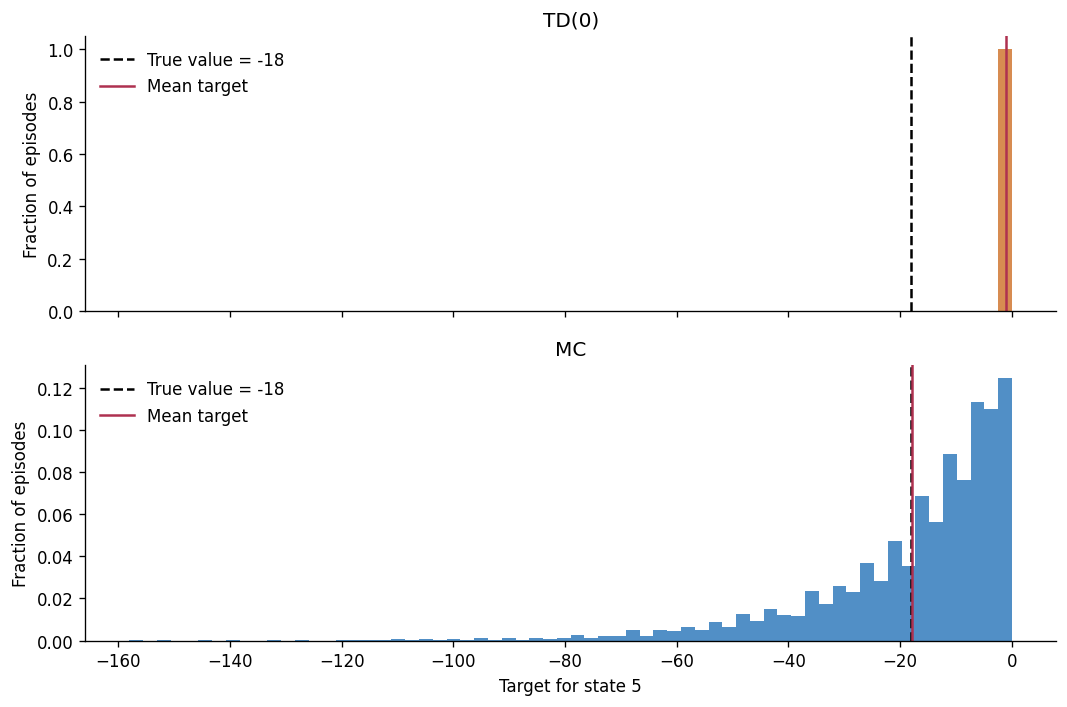

In [33]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
bins = np.linspace(min(grid_mc_targets.min(), -18)-1, 0, 65)
for ax, (name, values) in zip(axes, grid_targets.items()):
    ax.hist(values, bins=bins, weights=np.ones(len(values))/len(values),
            color=COLORS[name], alpha=0.8)
    ax.axvline(grid_truth[5], color="black", linestyle="--", label="True value = -18")
    ax.axvline(values.mean(), color="#ae3150", label="Mean target")
    ax.set(title=name, ylabel="Fraction of episodes")
    ax.legend(frameon=False)
axes[-1].set_xlabel("Target for state 5")
fig.tight_layout()
plt.show()

The MC targets have a wide spread, but their mean is close to $-18$. The TD targets have no spread, but their mean is 17 units too high.

The gap between the mean and the true value shows bias. The spread around the mean shows variance. Increasing the number of samples makes our measurements more precise. It does not remove TD's bias while its bootstrap values remain frozen at zero.

### Where Does the MC Variance Come From?

In this environment, each reward is a constant. The randomness comes from the episode length $T$:

$$G_0=-T,\qquad \operatorname{Var}(G_0)=\operatorname{Var}(T).$$

The histogram groups returns, rather than states. A return of $-20$ means the episode took 20 steps. States can be revisited, so an episode can take more steps than there are states.

Also, the variance of a single return is different from the variance of an average of returns. Averaging $M$ independent MC returns divides their variance by $M$. Averaging the frozen TD targets still gives $-1$.

## Experiment 2: Letting the Methods Learn

The frozen experiment isolates the targets. Now we'll update the value estimates and repeat the entire training process 500 times.

Each run starts with a zero value table. Both methods receive the same episodes within that run. TD updates after every transition. First-visit MC waits for termination and then updates each visited state using the return following its first visit in that episode.

We use a constant learning rate of 0.05. At each checkpoint, we collect the 500 learned estimates of state 5. Bias and variance are now measured across training runs, rather than across individual targets.

### Training Implementation

The runs are batched for speed. Each row has its own value table and trajectory. We keep the first-visit time for MC; because rewards are all $-1$, the remaining return is minus the number of remaining transitions.

In [12]:
GRID_START = 5
NONTERMINALS = np.arange(1, 15)

In [13]:
def grid_transition_table():
    transitions = np.empty((GRID_NUM_STATES, 4), dtype=int)

    for state in range(GRID_NUM_STATES):
        for action in range(4):
            transitions[state, action] = grid_next_state(state, action)

    return transitions

In [14]:
def train_gridworld(
    num_runs, num_episodes, alpha, seed, checkpoints, max_steps=100_000
):
    rng = np.random.default_rng(seed)
    transitions = grid_transition_table()

    # Each row is a separate training run with its own value table.
    V_td = np.zeros((num_runs, GRID_NUM_STATES))
    V_mc = np.zeros_like(V_td)
    td_history = []
    mc_history = []
    checkpoints = set(checkpoints)

    for episode in range(1, num_episodes + 1):
        states = np.full(num_runs, GRID_START, dtype=int)
        active = np.ones(num_runs, dtype=bool)
        episode_lengths = np.zeros(num_runs, dtype=int)
        first_visit_time = np.full((num_runs, GRID_NUM_STATES), -1, dtype=int)

        for step in range(max_steps):
            run_indices = np.flatnonzero(active)
            current_states = states[run_indices]

            # Save when each state was first visited in this episode.
            first_visits = first_visit_time[run_indices, current_states] == -1
            new_runs = run_indices[first_visits]
            new_states = current_states[first_visits]
            first_visit_time[new_runs, new_states] = step

            actions = rng.integers(4, size=len(run_indices))
            next_states = transitions[current_states, actions]
            terminated = np.isin(next_states, GRID_TERMINALS)

            # TD updates immediately, using zero beyond a terminal state.
            next_values = V_td[run_indices, next_states]
            bootstrap_values = np.where(terminated, 0.0, next_values)
            targets = -1.0 + bootstrap_values
            current_values = V_td[run_indices, current_states]
            td_errors = targets - current_values
            V_td[run_indices, current_states] += alpha * td_errors

            states[run_indices] = next_states
            episode_lengths[run_indices] += 1
            active[run_indices[terminated]] = False

            if not active.any():
                break
        else:
            raise RuntimeError("Episode exceeded max_steps; no truncated return used.")

        # The first-visit MC return is minus the remaining episode length.
        run_indices, visited_states = np.nonzero(first_visit_time >= 0)
        visit_times = first_visit_time[run_indices, visited_states]
        remaining_steps = episode_lengths[run_indices] - visit_times
        returns = -remaining_steps.astype(float)

        current_values = V_mc[run_indices, visited_states]
        mc_errors = returns - current_values
        V_mc[run_indices, visited_states] += alpha * mc_errors

        if episode in checkpoints:
            td_history.append(V_td.copy())
            mc_history.append(V_mc.copy())

    return {
        "TD(0)": np.asarray(td_history),
        "MC": np.asarray(mc_history),
    }

In [15]:
grid_history = train_gridworld(
    config.runs,
    config.episodes,
    config.alpha,
    config.seed,
    checkpoints,
)

grid_learned = {}
final_grid_estimates = {}

for method, history in grid_history.items():
    grid_learned[method] = history[:, :, 5]
    final_grid_estimates[method] = history[-1, :, 5]

grid_learning_statistics = comparison_table(final_grid_estimates, grid_truth[5])
display(grid_learning_statistics.round(6))

,mean,bias,bias_squared,variance,mse
Method,,,,,
TD(0),-17.238376,0.761624,0.580072,0.953658,1.53373
MC,-17.905529,0.094471,0.008925,7.454926,7.46385


Let's look at the learning curves

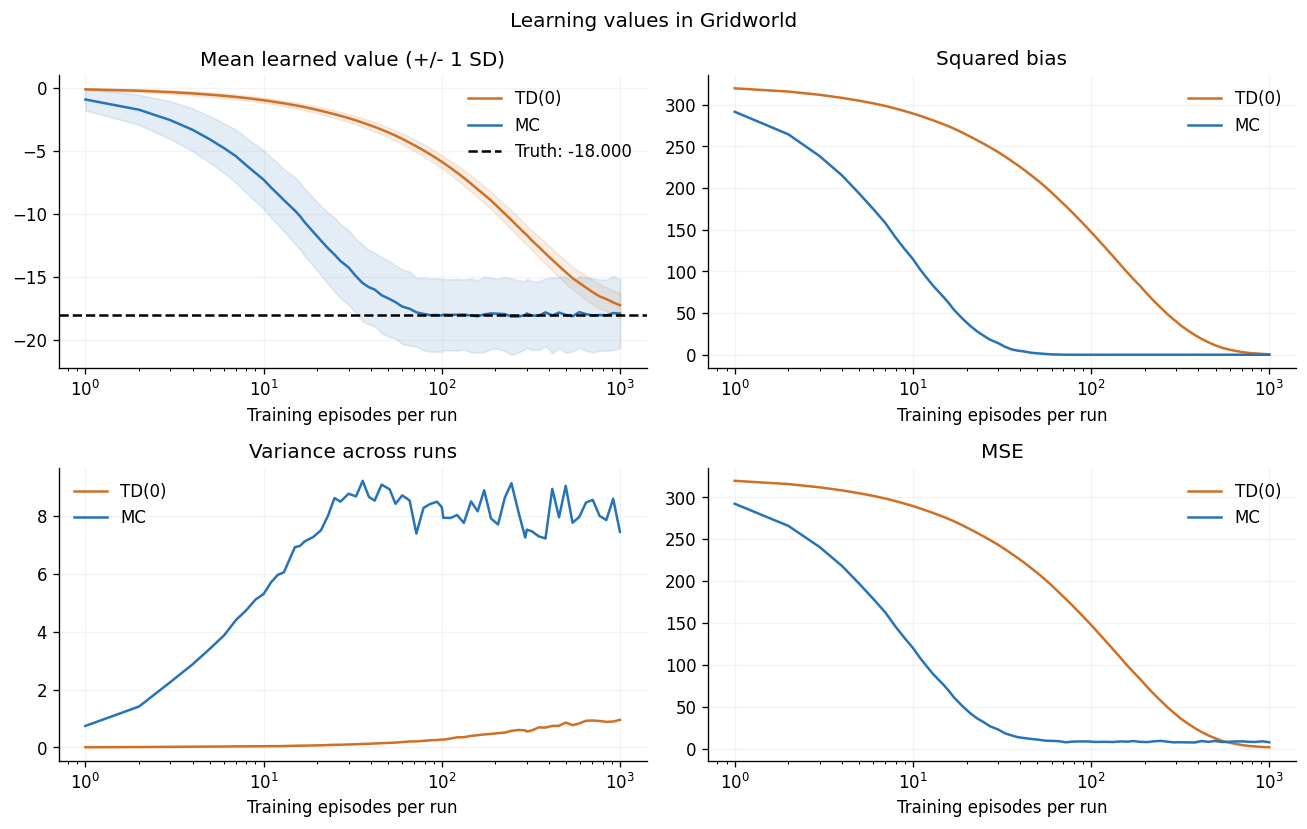

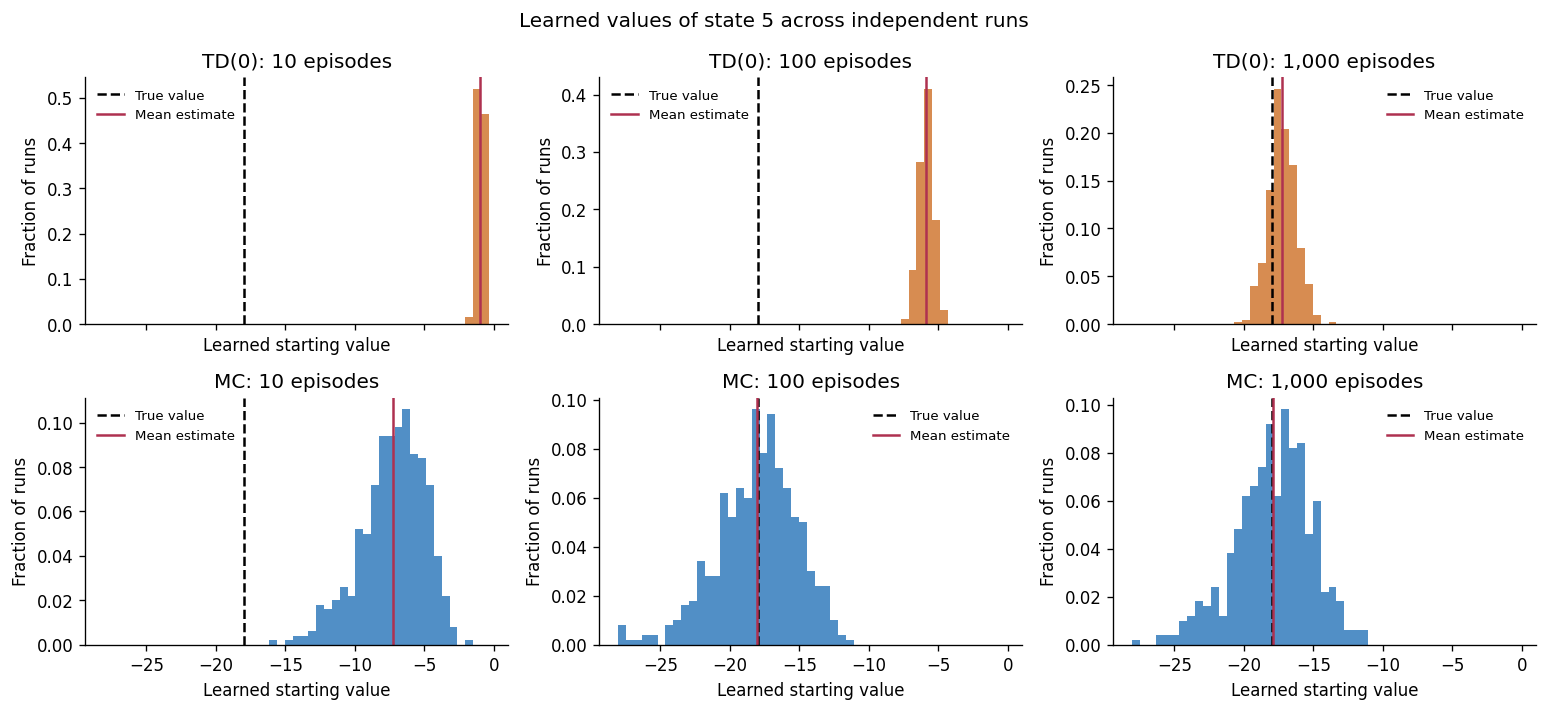

In [35]:
plot_learning_curves(
    grid_learned, checkpoints, grid_truth[5],
    "Learning values in Gridworld", "gridworld_learning_curves.png",
)

plot_learned_distributions(
    grid_learned, checkpoints, grid_truth[5],
    "Learned values of state 5 across independent runs",
    "gridworld_value_distributions.png",
)

MC moves toward the correct mean faster in this experiment, but its learned estimates remain more spread out. TD moves more slowly from its initial estimates, while producing a tighter distribution across runs. After enough training, TD's smaller variance outweighs its remaining bias at this learning rate.

An unbiased MC target does not imply an unbiased estimate after a finite amount of training. For a state visited once per episode, constant-$\alpha$ MC retains initialization bias:

$$\mathbb{E}[\hat V_K]-v=(1-\alpha)^K\left[\hat V_0-v\right].$$

The random episode lengths supply the noise in the MC targets. The update rule determines how much of that noise remains in the learned estimates. A constant learning rate keeps admitting fresh noise, so the distribution does not collapse to a point as it would for an ordinary sample average of independent returns.

This Gridworld comparison gives TD more updates when a state is revisited within an episode. MC uses first visits. Equal episode data therefore doesn't mean equal update counts. We'll remove that difference in the fixed-horizon experiments.

## Experiment 3: Fixing the Episode Length

Variable episode length is one source of return variance. It is not the only one. Next, we'll keep every episode at exactly 20 steps and introduce random rewards.

The environment has two physical states, A and B. The policy stays in the current state with probability 0.8 and switches with probability 0.2. Leaving A gives a reward of $-2$ or 0, equally likely. Leaving B gives a reward of 0 or $+2$, equally likely. Fresh reward noise is independent of the action and earlier reward noise.

![Two-state environment and the fixed prediction horizon.](two_state_environment.png)

Two-state environment and the fixed prediction horizon.

### Keeping Track of the Horizon

The physical process has no absorbing state. Our prediction objective ends after 20 transitions. To make TD and MC estimate the same quantity, we include the number of steps remaining in the prediction state:

$$V(h,s),\qquad V(0,s)=0.$$

We are estimating a finite-horizon return, not the infinite-horizon value of a continuing task. The clock is part of the state used by the learner.

### True Values and Training

The transition matrix under the policy is $P=\left[\begin{smallmatrix}0.8&0.2\\0.2&0.8\end{smallmatrix}\right]$, and the expected rewards are $r=(-1,+1)$. We calculate the reference values recursively:

$$v_h=r+\gamma P v_{h-1},\qquad v_0=0.$$

The following functions compute the exact moments and train the two methods. Every episode starts in A. Each augmented state $(h,s)$ can appear at most once per episode, so both methods make the same number of value updates.

In [17]:
def two_state_exact_moments(horizon, gamma):
    transition_probabilities = np.array([
        [0.8, 0.2],
        [0.2, 0.8],
    ])
    expected_rewards = np.array([-1.0, 1.0])

    values = np.zeros((horizon + 1, 2))
    return_variances = np.zeros_like(values)

    for steps_remaining in range(1, horizon + 1):
        next_values = values[steps_remaining - 1]
        expected_next_value = transition_probabilities @ next_values
        values[steps_remaining] = expected_rewards + gamma * expected_next_value

        # Immediate reward noise has variance 1 and is independent of the move.
        next_variances = return_variances[steps_remaining - 1]
        next_second_moments = next_variances + next_values**2
        expected_second_moment = transition_probabilities @ next_second_moments
        future_variance = expected_second_moment - expected_next_value**2
        return_variances[steps_remaining] = 1.0 + gamma**2 * future_variance

    return values, return_variances

In [18]:
def train_two_state(runs, episodes, horizon, gamma, alpha, seed, checkpoints):
    rng = np.random.default_rng(seed)
    run_indices = np.arange(runs)

    # Values are indexed by run, steps remaining, and physical state.
    V_td = np.zeros((runs, horizon + 1, 2))
    V_mc = np.zeros_like(V_td)
    td_history = []
    mc_history = []

    for episode in range(1, episodes + 1):
        current_states = np.zeros(runs, dtype=int)  # Start in A.
        episode_states = np.empty((horizon, runs), dtype=int)
        episode_rewards = np.empty((horizon, runs))

        for step in range(horizon):
            steps_remaining = horizon - step
            episode_states[step] = current_states

            # A has mean reward -1; B has mean reward +1.
            reward_means = 2 * current_states - 1
            reward_noise = 2 * rng.integers(2, size=runs) - 1
            rewards = reward_means + reward_noise

            switch_states = rng.random(runs) < 0.2
            next_states = np.where(switch_states, 1 - current_states, current_states)
            episode_rewards[step] = rewards

            next_values = V_td[run_indices, steps_remaining - 1, next_states]
            targets = rewards + gamma * next_values
            current_values = V_td[run_indices, steps_remaining, current_states]
            td_errors = targets - current_values
            V_td[run_indices, steps_remaining, current_states] += alpha * td_errors

            current_states = next_states

        # Work backward to calculate each complete remaining return for MC.
        returns = np.zeros(runs)

        for step in range(horizon - 1, -1, -1):
            steps_remaining = horizon - step
            states = episode_states[step]
            returns = episode_rewards[step] + gamma * returns

            current_values = V_mc[run_indices, steps_remaining, states]
            mc_errors = returns - current_values
            V_mc[run_indices, steps_remaining, states] += alpha * mc_errors

        if episode in checkpoints:
            td_history.append(V_td.copy())
            mc_history.append(V_mc.copy())

    return {
        "TD(0)": np.asarray(td_history),
        "MC": np.asarray(mc_history),
    }

In [19]:
two_state_truth, two_state_return_variance = two_state_exact_moments(
    config.horizon, config.gamma
)

two_state_history = train_two_state(
    config.runs,
    config.episodes,
    config.horizon,
    config.gamma,
    config.alpha,
    config.seed,
    set(checkpoints),
)

two_state_learned = {}
final_two_state_estimates = {}

for method, history in two_state_history.items():
    starting_estimates = history[:, :, config.horizon, 0]
    two_state_learned[method] = starting_estimates
    final_two_state_estimates[method] = starting_estimates[-1]

print(f"True 20-step value from A: {two_state_truth[-1, 0]:.6f}")
two_state_statistics = comparison_table(
    final_two_state_estimates, two_state_truth[-1, 0]
)
display(two_state_statistics.round(6))

True 20-step value from A: -2.173903


,mean,bias,bias_squared,variance,mse
Method,,,,,
TD(0),-2.174080,-0.000176,0.000000,0.174972,0.174972
MC,-2.171911,0.001993,0.000004,0.434774,0.434778


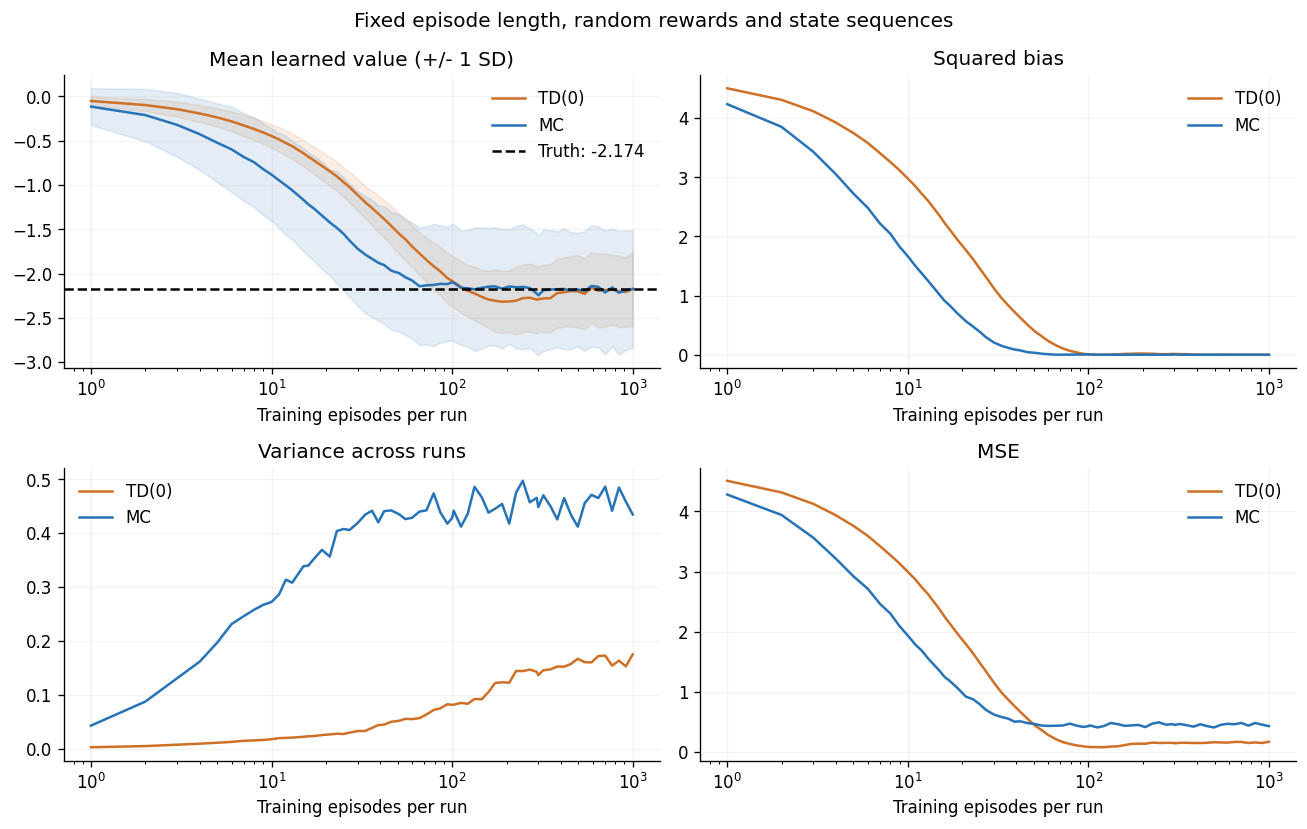

In [36]:
plot_learning_curves(
    two_state_learned, checkpoints, two_state_truth[-1, 0],
    "Fixed episode length, random rewards and state sequences",
    "two_state_learning_curves.png",
)

The MC estimates still have more variance here, even though episode length is fixed. Different state sequences and reward draws produce different returns. By the end of training, both methods' mean estimates are close to the reference value, while TD's distribution is narrower.

The rewards in this example are not independent overall. Remaining in A or B changes the expected rewards of subsequent transitions. Their variances therefore don't simply add: a general variance calculation includes covariance terms as well as squared discount factors.

## Experiment 4: Isolating Independent Reward Noise

We can simplify the environment further. Keep one physical state and one action. At every step, sample a reward independently: 0 or $-2$, each with probability $1/2$. Keep the horizon at 20 and the discount at 0.9.

Now the trajectory and episode length are fixed. Only the rewards vary. Each reward has mean $-1$ and variance 1.

![One physical state with independent rewards and a deterministic prediction clock.](one_state_environment.png)

One physical state with independent rewards and a deterministic prediction clock.

### Adding Independent Reward Noise

The true value with $h$ steps remaining is:

$$v_h=-\sum_{k=0}^{h-1}\gamma^k.$$

Because the rewards are independent, the full return's variance is:

$$\operatorname{Var}(G_0)=\sum_{k=0}^{19}\gamma^{2k}\operatorname{Var}(R_{k+1})
=\sum_{k=0}^{19}0.9^{2k}\approx5.185.$$

This is the setting where adding more independent random rewards directly adds variance, weighted by squared discounts.

We still learn a separate estimate for each remaining horizon. Although the physical state is unchanged, there are 20 nonterminal prediction states. We deliberately don't tie those estimates together or estimate the shared reward mean and solve the task from that structure.

### Learning and Exact Predictions

The training function below also tracks exact means and covariances. In this deterministic clock, the TD update for horizon $h$ uses the previous episode's estimate for $h-1$: that later prediction state has not yet been updated when the current update occurs. This lets us express one episode as a linear update plus independent reward noise.

If $B$ is that update matrix, the covariance follows $C_{K+1}=BC_KB^T+\alpha^2I$. For MC's starting estimate, independent episodes give:

$$\operatorname{Var}(\hat V_K)=\frac{\alpha}{2-\alpha}
\left[1-(1-\alpha)^{2K}\right]\operatorname{Var}(G_0).$$

These calculations provide a check on the simulation, rather than another estimate from the same 500 runs.

In [21]:
def noise_exact_values(horizon, gamma):
    values = np.zeros(horizon + 1)

    for steps_remaining in range(1, horizon + 1):
        expected_reward = -1.0
        next_value = values[steps_remaining - 1]
        values[steps_remaining] = expected_reward + gamma * next_value

    return values

In [22]:
def run_noise_learning(runs, episodes, horizon, gamma, alpha, seed, checkpoints):
    rng = np.random.default_rng(seed)
    true_values = noise_exact_values(horizon, gamma)

    V_td = np.zeros((runs, horizon + 1))
    V_mc = np.zeros_like(V_td)
    td_history = []
    mc_history = []
    td_exact_history = []
    mc_exact_history = []

    # One episode retains part of each estimate and bootstraps from h - 1.
    update_matrix = (1 - alpha) * np.eye(horizon)
    bootstrap_matrix = np.eye(horizon, k=-1)
    update_matrix += alpha * gamma * bootstrap_matrix

    td_mean = np.zeros(horizon)
    td_covariance = np.zeros((horizon, horizon))
    reward_covariance = alpha**2 * np.eye(horizon)
    discount_weights = gamma ** np.arange(horizon)
    full_return_variance = np.sum(discount_weights**2)

    for episode in range(1, episodes + 1):
        rewards = -2.0 * rng.integers(2, size=(runs, horizon))

        # TD follows the clock from the full horizon down to one remaining step.
        for step in range(horizon):
            steps_remaining = horizon - step
            next_values = V_td[:, steps_remaining - 1]
            targets = rewards[:, step] + gamma * next_values
            td_errors = targets - V_td[:, steps_remaining]
            V_td[:, steps_remaining] += alpha * td_errors

        # MC uses the same rewards, but waits for the complete episode.
        returns = np.zeros(runs)

        for step in range(horizon - 1, -1, -1):
            steps_remaining = horizon - step
            returns = rewards[:, step] + gamma * returns
            mc_errors = returns - V_mc[:, steps_remaining]
            V_mc[:, steps_remaining] += alpha * mc_errors

        # Track the exact moments separately from the sampled training runs.
        td_mean = update_matrix @ td_mean - alpha
        propagated_covariance = update_matrix @ td_covariance @ update_matrix.T
        td_covariance = propagated_covariance + reward_covariance

        retained_initial_weight = (1 - alpha) ** episode
        mc_mean = true_values[-1] * (1 - retained_initial_weight)
        mc_variance_scale = alpha / (2 - alpha)
        mc_variance = mc_variance_scale * full_return_variance
        mc_variance *= 1 - retained_initial_weight**2

        if episode in checkpoints:
            td_history.append(V_td.copy())
            mc_history.append(V_mc.copy())
            td_exact_history.append((td_mean[-1], td_covariance[-1, -1]))
            mc_exact_history.append((mc_mean, mc_variance))

    histories = {
        "TD(0)": np.asarray(td_history),
        "MC": np.asarray(mc_history),
    }
    exact_moments = {
        "TD(0)": np.asarray(td_exact_history),
        "MC": np.asarray(mc_exact_history),
    }
    return histories, exact_moments

In [23]:
noise_history, noise_exact = run_noise_learning(
    config.runs,
    config.episodes,
    config.horizon,
    config.gamma,
    config.alpha,
    config.seed,
    set(checkpoints),
)

noise_truth = noise_exact_values(config.horizon, config.gamma)[-1]
noise_learned = {}
final_noise_estimates = {}

for method, history in noise_history.items():
    noise_learned[method] = history[:, :, -1]
    final_noise_estimates[method] = history[-1, :, -1]

discount_weights = config.gamma ** np.arange(config.horizon)
full_return_variance = np.sum(discount_weights**2)

print(f"True starting value: {noise_truth:.6f}")
print(f"Variance of a full MC return: {full_return_variance:.6f}")

noise_table = comparison_table(final_noise_estimates, noise_truth)
noise_table["exact_variance"] = np.nan

for method in noise_table.index:
    noise_table.loc[method, "exact_variance"] = noise_exact[method][-1, 1]

display(noise_table.round(6))

True starting value: -8.784233
Variance of a full MC return: 5.185364


,mean,bias,bias_squared,variance,mse,exact_variance
Method,,,,,,
TD(0),-8.785569,-0.001335,0.000002,0.056902,0.056904,0.058610
MC,-8.776084,0.008150,0.000066,0.133551,0.133618,0.132958


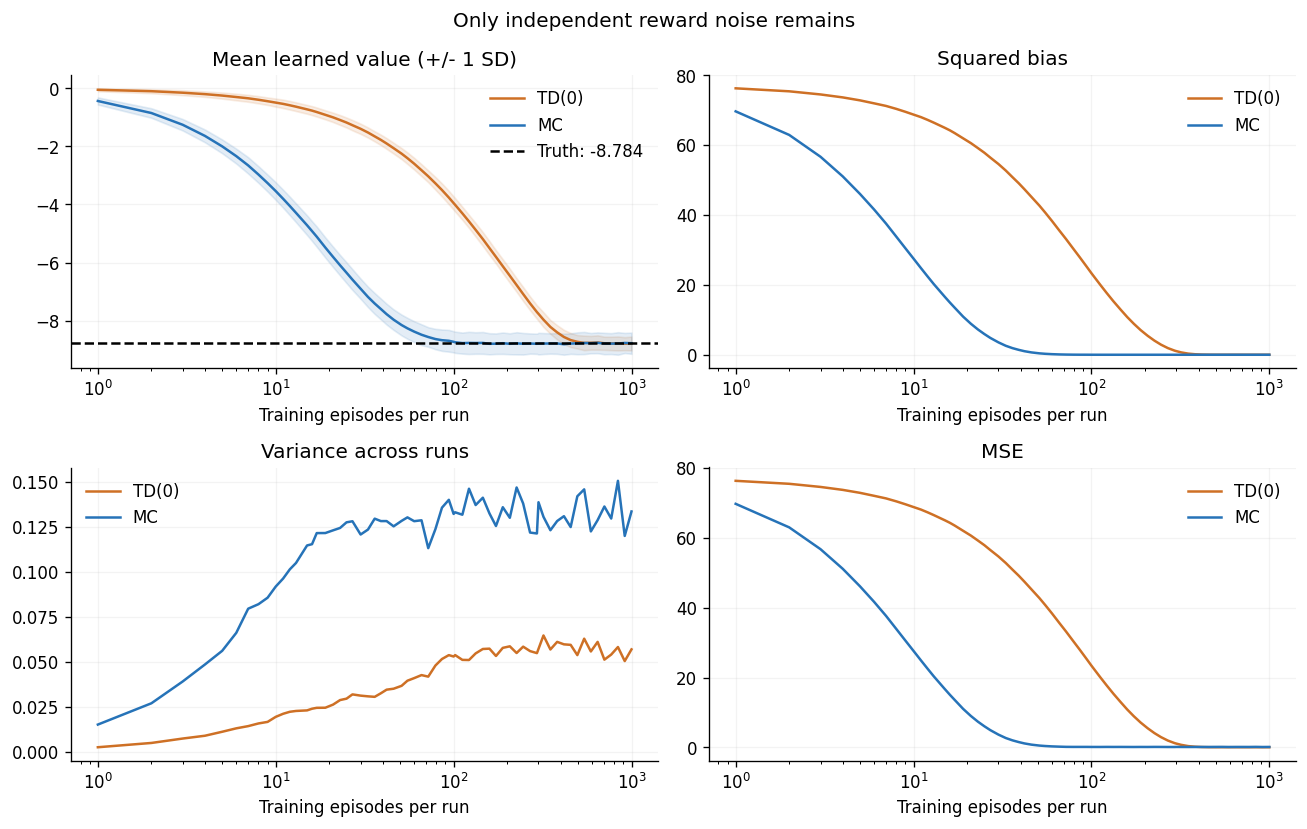

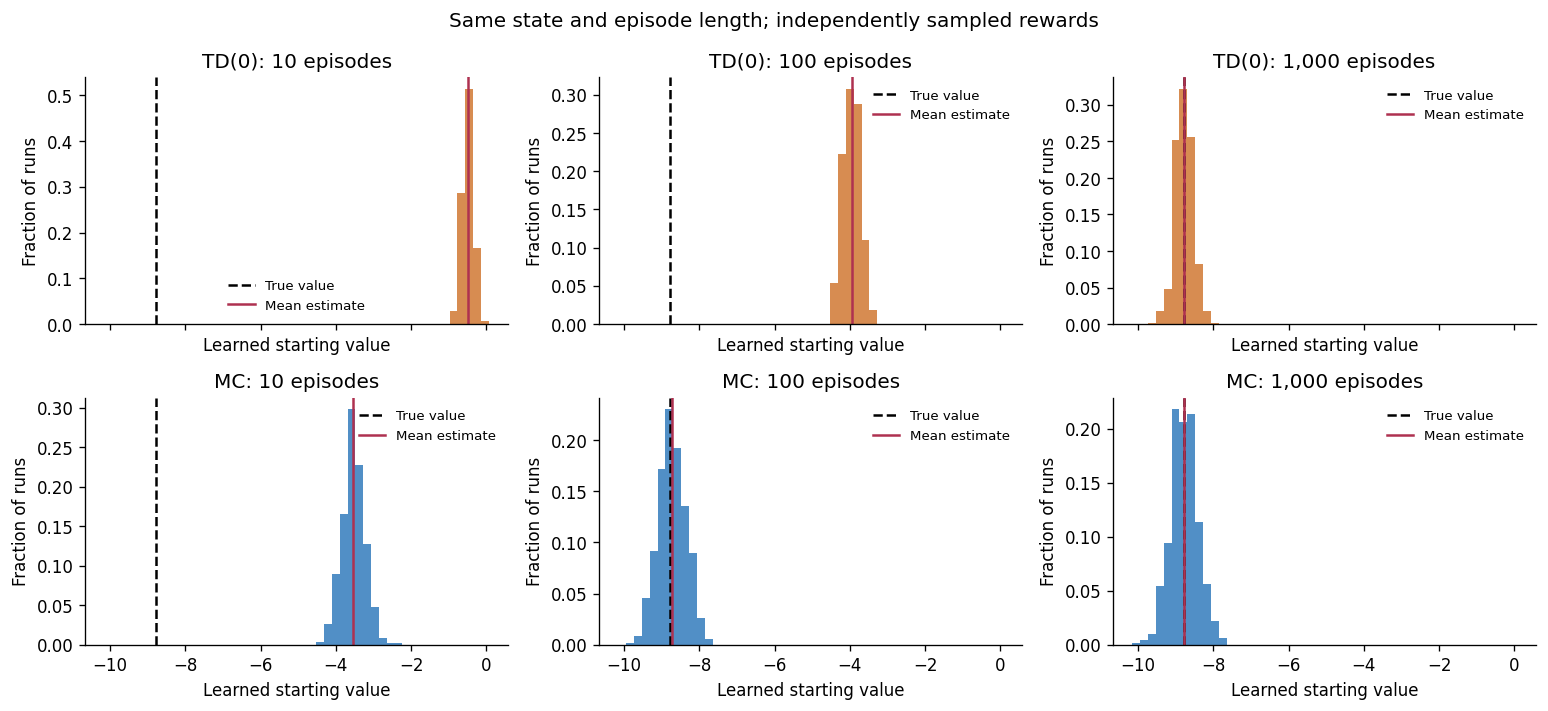

In [37]:
plot_learning_curves(
    noise_learned, checkpoints, noise_truth,
    "Only independent reward noise remains", "one_state_learning_curves.png",
)

plot_learned_distributions(
    noise_learned, checkpoints, noise_truth,
    "Same state and episode length; independently sampled rewards",
    "one_state_value_distributions.png",
)

The variance difference remains. MC learns from the whole sampled reward sequence. TD combines one sampled reward with a learned estimate of the rest. Once those estimates become accurate, TD achieves lower variance and lower MSE in this experiment.

The value 5.185 above is the variance of one MC return. It is different from the variance of the learned estimate in the table. Learning averages noisy targets, so the update rule and learning rate determine how much variability remains.

## Experiment 5: Fixing the Bootstrap Error

During learning, the bootstrap estimates change. To examine the mechanism directly, we'll freeze them at a known error instead:

$$\hat V(h)=v_h+2\quad\text{for }h>0,\qquad\hat V(0)=0.$$

Every nonterminal estimate is two units too high. The zero-horizon value remains exactly zero.

### Comparing Backup Lengths

An n-step target samples $n$ rewards before using a value estimate for the remainder:

$$Y_n=\sum_{k=0}^{n-1}\gamma^kR_{k+1}+\gamma^n\hat V(20-n).$$

For $n=1$, this is the TD(0) target. For $n=20$, it is full MC with no bootstrap term. For $n<20$, its bias and variance are:

$$\operatorname{Bias}(Y_n)=2\gamma^n,\qquad
\operatorname{Var}(Y_n)=\sum_{k=0}^{n-1}\gamma^{2k}.$$

The bias is zero at $n=20$. Longer backups discount the bootstrap error more heavily while adding independent reward noise. We'll collect 100,000 trajectories and reuse each trajectory across all backup lengths.

In [25]:
def sample_nstep_targets(
    samples=100_000, horizon=20, gamma=0.9, error=2.0, seed=42
):
    rng = np.random.default_rng(seed)
    backup_lengths = np.arange(1, horizon + 1)
    discount_weights = gamma ** np.arange(horizon)

    true_values = noise_exact_values(horizon, gamma)
    frozen_values = true_values + error
    frozen_values[0] = 0.0  # The return beyond the horizon is exactly zero.

    rewards = -2.0 * rng.integers(2, size=(samples, horizon))
    targets = np.zeros((samples, horizon))
    sampled_returns = np.zeros(samples)
    exact_bias = np.zeros(horizon)
    exact_variance = np.zeros(horizon)

    for index, n in enumerate(backup_lengths):
        # Add one more discounted reward to the sampled part of the target.
        sampled_returns += discount_weights[index] * rewards[:, index]

        steps_remaining = horizon - n
        bootstrap_value = frozen_values[steps_remaining]
        targets[:, index] = sampled_returns + gamma**n * bootstrap_value

        if steps_remaining > 0:
            exact_bias[index] = error * gamma**n

        exact_variance[index] = np.sum(discount_weights[:n] ** 2)

    truth = true_values[-1]
    statistics = prediction_statistics(targets, truth, axis=0)
    exact_mse = exact_bias**2 + exact_variance

    # The full-horizon target must be the actual Monte Carlo return.
    np.testing.assert_allclose(targets[:, -1], rewards @ discount_weights)

    return {
        "n": backup_lengths,
        "targets": targets,
        "truth": truth,
        "mean": statistics["mean"],
        "bias": statistics["bias"],
        "variance": statistics["variance"],
        "mse": statistics["mse"],
        "theoretical_bias": exact_bias,
        "theoretical_variance": exact_variance,
        "theoretical_mse": exact_mse,
    }

In [26]:
frozen_nstep = sample_nstep_targets(
    config.target_samples,
    config.horizon,
    config.gamma,
    error=2.0,
    seed=config.seed,
)

target_rows = []

for n in (1, 2, 5, 20):
    index = n - 1
    row = {
        "n": n,
        "exact_bias": frozen_nstep["theoretical_bias"][index],
        "exact_variance": frozen_nstep["theoretical_variance"][index],
        "exact_mse": frozen_nstep["theoretical_mse"][index],
        "measured_mse": frozen_nstep["mse"][index],
    }
    target_rows.append(row)

target_table = pd.DataFrame(target_rows).set_index("n")
display(target_table.round(6))

,exact_bias,exact_variance,exact_mse,measured_mse
n,,,,
1,1.80000,1.000000,4.240000,4.237912
2,1.62000,1.810000,4.434400,4.427898
5,1.18098,3.428008,4.822722,4.830325
20,0.00000,5.185364,5.185364,5.202145


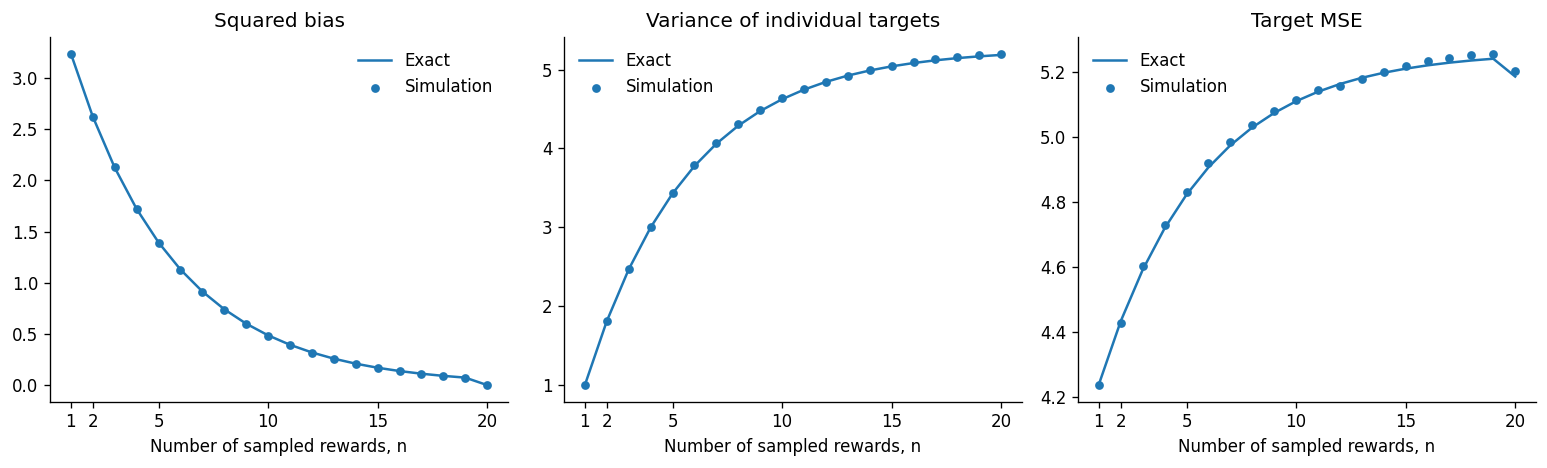

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, key, title in zip(axes, ("bias", "variance", "mse"),
                          ("Squared bias", "Variance of individual targets", "Target MSE")):
    observed = frozen_nstep[key]**2 if key == "bias" else frozen_nstep[key]
    exact = frozen_nstep["theoretical_bias"]**2 if key == "bias" else frozen_nstep["theoretical_"+key]
    ax.plot(frozen_nstep["n"], exact, label="Exact")
    ax.scatter(frozen_nstep["n"], observed, s=18, label="Simulation")
    ax.set(title=title, xlabel="Number of sampled rewards, n", xticks=[1, 2, 5, 10, 15, 20])
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()

The two components move in opposite directions. Bias falls as the backup gets longer, while variance rises. For this particular two-unit error, the one-step target has the lowest MSE. A tradeoff does not require the optimum to be an intermediate backup length.

These are statistics of individual targets with fixed bootstrap values. There is no learning in this experiment. A larger bootstrap error would change the MSE comparison, while leaving the reward-noise variance unchanged.

## Experiment 6: Learning with n-Step Returns

Finally, we'll allow all the n-step methods to learn. We compare every backup length from 1 through 20 on the same data. Each run starts from zero, and each method updates every remaining-horizon value once per episode.

The n-step target uses the current learned estimate of the remaining return. If the horizon ends before $n$ rewards are available, we use the complete remaining return and no bootstrap term.

### Exact Mean and Covariance Updates

The clock makes the dependencies particularly simple. With a fixed backup length, an episode can be written as:

$$\hat{\boldsymbol V}_{K+1}=B_n\hat{\boldsymbol V}_K+\alpha W_n\boldsymbol R_K.$$

$W_n$ collects the discounted reward prefixes. $B_n$ retains part of each current estimate and adds the appropriate bootstrap contribution. Different prefixes overlap, so we keep their covariance rather than treating learned horizons as independent.

Since reward components have mean $-1$ and covariance $I$:

$$m_{K+1}=B_nm_K-\alpha W_n\boldsymbol 1,$$

$$C_{K+1}=B_nC_KB_n^T+\alpha^2W_nW_n^T.$$

The following helper constructs those exact updates for each backup length.

In [28]:
def n_step_operators(horizon, gamma, alpha):
    num_methods = horizon
    reward_weights = np.zeros((num_methods, horizon, horizon))
    bootstrap_weights = np.zeros_like(reward_weights)

    for method_index in range(num_methods):
        n = method_index + 1

        for steps_remaining in range(1, horizon + 1):
            row = steps_remaining - 1
            first_reward_horizon = max(1, steps_remaining - n + 1)

            for reward_horizon in range(first_reward_horizon, steps_remaining + 1):
                column = reward_horizon - 1
                discount = gamma ** (steps_remaining - reward_horizon)
                reward_weights[method_index, row, column] = discount

            if steps_remaining > n:
                column = steps_remaining - n - 1
                bootstrap_weights[method_index, row, column] = gamma**n

    update_matrices = np.zeros_like(reward_weights)
    noise_covariances = np.zeros_like(reward_weights)
    reward_offsets = np.zeros((num_methods, horizon))

    for method_index in range(num_methods):
        weights = reward_weights[method_index]
        bootstrap = bootstrap_weights[method_index]

        update_matrices[method_index] = (1 - alpha) * np.eye(horizon)
        update_matrices[method_index] += alpha * bootstrap
        noise_covariances[method_index] = alpha**2 * (weights @ weights.T)
        reward_offsets[method_index] = -alpha * weights.sum(axis=1)

    return update_matrices, noise_covariances, reward_offsets

### Training All Backup Lengths

The implementation keeps the independent runs in separate rows and loops over the backup lengths explicitly. Within each method, we follow the clock from the full horizon down to one remaining step. A bootstrap state with fewer steps remaining has not yet had its own update, so the update reads its pre-episode estimate. This matches online n-step TD for this acyclic clock. The equivalence would need to be reconsidered in an environment that revisits the same prediction state.

In [29]:
def run_n_step_learning(
    runs=500, episodes=1000, horizon=20, gamma=0.9, alpha=0.05, seed=42
):
    rng = np.random.default_rng(seed)
    backup_lengths = np.arange(1, horizon + 1)
    num_methods = len(backup_lengths)
    true_values = noise_exact_values(horizon, gamma)

    early_episodes = np.arange(1, min(episodes, 10) + 1)
    later_episodes = np.geomspace(1, episodes, min(episodes, 80)).astype(int)
    fixed_budgets = []
    for budget in (10, 30, 100, 300, 1000):
        if budget <= episodes:
            fixed_budgets.append(budget)

    checkpoints = np.concatenate((early_episodes, later_episodes, fixed_budgets, [episodes]))
    checkpoints = np.unique(checkpoints).astype(int)

    # The three dimensions are backup length, training run, and remaining horizon.
    values = np.zeros((num_methods, runs, horizon + 1))
    learned_history = []
    exact_mean_history = []
    exact_variance_history = []

    update_matrices, noise_covariances, reward_offsets = n_step_operators(
        horizon, gamma, alpha
    )
    exact_means = np.zeros((num_methods, horizon))
    exact_covariances = np.zeros((num_methods, horizon, horizon))

    for episode in range(1, episodes + 1):
        # Column h-1 is the reward observed with h steps remaining.
        # Every method receives the same rewards within each training run.
        rewards = -2.0 * rng.integers(2, size=(runs, horizon))
        sampled_returns = np.zeros((runs, horizon + 1))

        for method_index, n in enumerate(backup_lengths):
            # Extend the sampled return by one reward as n increases.
            # When fewer than n steps remain, the full return is already available.
            for steps_remaining in range(n, horizon + 1):
                reward = rewards[:, steps_remaining - n]
                discounted_reward = gamma ** (n - 1) * reward
                sampled_returns[:, steps_remaining] += discounted_reward

            # Follow the clock forward: h decreases from the full horizon to 1.
            for steps_remaining in range(horizon, 0, -1):
                targets = sampled_returns[:, steps_remaining].copy()

                if steps_remaining > n:
                    bootstrap_horizon = steps_remaining - n
                    bootstrap_values = values[method_index, :, bootstrap_horizon]
                    targets += gamma**n * bootstrap_values

                current_values = values[method_index, :, steps_remaining]
                td_errors = targets - current_values
                values[method_index, :, steps_remaining] += alpha * td_errors

            # Propagate exact moments for this method independently of the samples.
            update_matrix = update_matrices[method_index]
            expected_values = exact_means[method_index]
            covariance = exact_covariances[method_index]

            exact_means[method_index] = (
                update_matrix @ expected_values + reward_offsets[method_index]
            )
            exact_covariances[method_index] = (
                update_matrix @ covariance @ update_matrix.T
                + noise_covariances[method_index]
            )

        if episode in checkpoints:
            learned_history.append(values[:, :, -1].copy())
            exact_mean_history.append(exact_means[:, -1].copy())
            exact_variance_history.append(exact_covariances[:, -1, -1].copy())

    learned_history = np.asarray(learned_history)
    exact_mean_history = np.asarray(exact_mean_history)
    exact_variance_history = np.asarray(exact_variance_history)
    statistics = prediction_statistics(learned_history, true_values[-1], axis=2)
    exact_bias = exact_mean_history - true_values[-1]
    exact_mse = exact_bias**2 + exact_variance_history

    return {
        "checkpoints": checkpoints,
        "n": backup_lengths,
        "history": learned_history,
        "truth": true_values,
        "mean": statistics["mean"],
        "bias": statistics["bias"],
        "variance": statistics["variance"],
        "mse": statistics["mse"],
        "exact_mean": exact_mean_history,
        "exact_variance": exact_variance_history,
        "exact_mse": exact_mse,
        "final_values": values,
    }

In [30]:
n_step_results = run_n_step_learning(
    config.runs,
    config.episodes,
    config.horizon,
    config.gamma,
    config.alpha,
    config.seed,
)

budget_rows = []

for budget in (10, 100, 300, 1000):
    checkpoint_index = np.flatnonzero(n_step_results["checkpoints"] == budget)[0]
    exact_mse = n_step_results["exact_mse"][checkpoint_index]
    best_method_index = int(np.argmin(exact_mse))

    row = {
        "episodes": budget,
        "TD(0) MSE": exact_mse[0],
        "best n": best_method_index + 1,
        "best MSE": exact_mse[best_method_index],
        "MC MSE": exact_mse[-1],
    }
    budget_rows.append(row)

budget_table = pd.DataFrame(budget_rows).set_index("episodes")
display(budget_table.round(6))

,TD(0) MSE,best n,best MSE,MC MSE
episodes,,,,
10,68.829830,20,27.747057,27.747057
100,23.493652,20,0.135658,0.135658
300,1.114094,2,0.080703,0.132958
1000,0.058610,1,0.058610,0.132958


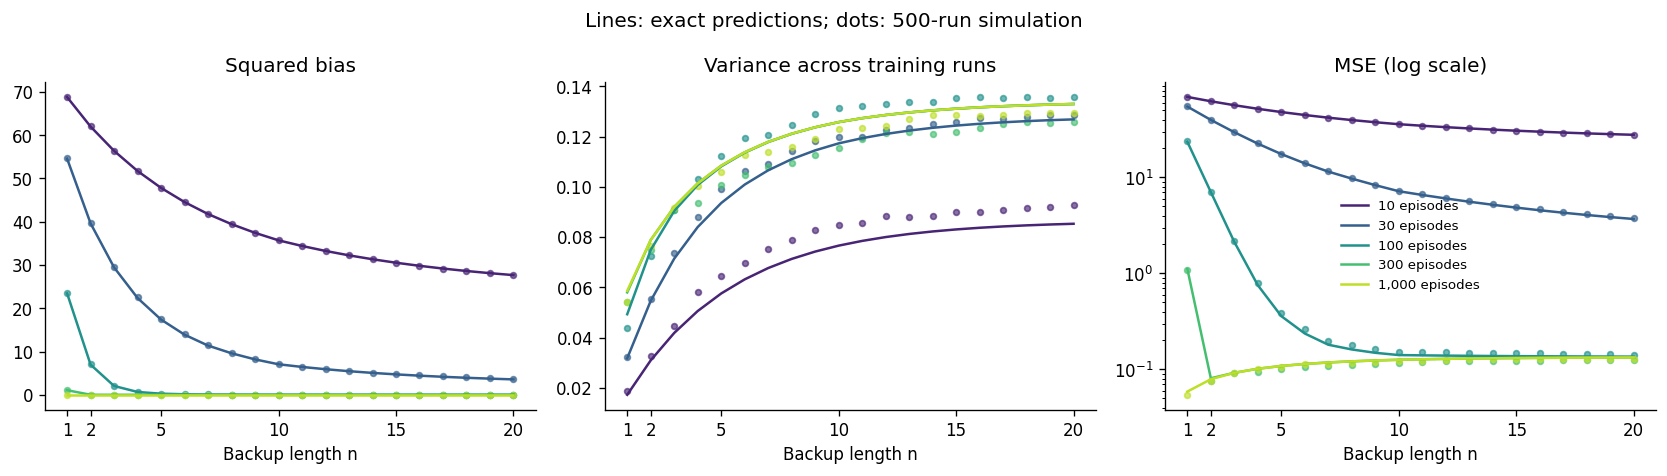

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
budgets = (10, 30, 100, 300, 1000)
for budget, color in zip(budgets, plt.cm.viridis(np.linspace(0.1, 0.9, len(budgets)))):
    k = np.flatnonzero(n_step_results["checkpoints"] == budget)[0]
    exact_bias = n_step_results["exact_mean"][k] - n_step_results["truth"][-1]
    for ax, key, exact in zip(axes, ("bias", "variance", "mse"),
            (exact_bias**2, n_step_results["exact_variance"][k], n_step_results["exact_mse"][k])):
        measured = n_step_results[key][k]**2 if key == "bias" else n_step_results[key][k]
        ax.plot(n_step_results["n"], exact, color=color, label=f"{budget:,} episodes")
        ax.scatter(n_step_results["n"], measured, color=color, s=12, alpha=0.65)
for ax, title in zip(axes, ("Squared bias", "Variance across training runs", "MSE (log scale)")):
    ax.set(title=title, xlabel="Backup length n", xticks=[1, 2, 5, 10, 15, 20])
axes[-1].set_yscale("log")
axes[-1].legend(frameon=False, fontsize=8)
fig.suptitle("Lines: exact predictions; dots: 500-run simulation")
fig.tight_layout()

The best backup length changes with the training budget. With 10 or 100 episodes, MC has the lowest MSE. It moves away from the zero initialization faster because its targets don't depend on unlearned future values.

After 300 episodes, two-step TD has the lowest MSE. It has removed enough bootstrap bias while keeping lower variance than MC. After 1,000 episodes, one-step TD has learned accurate enough bootstrap values for its smaller variance to give it the best MSE.

The table uses exact MSE, rather than choosing a winner from noisy simulation estimates. The dots show how the 500-run measurements compare with those predictions.

### Learning Curves

We can also follow selected backup lengths through training. The MSE panel uses a logarithmic scale so the later differences remain visible.

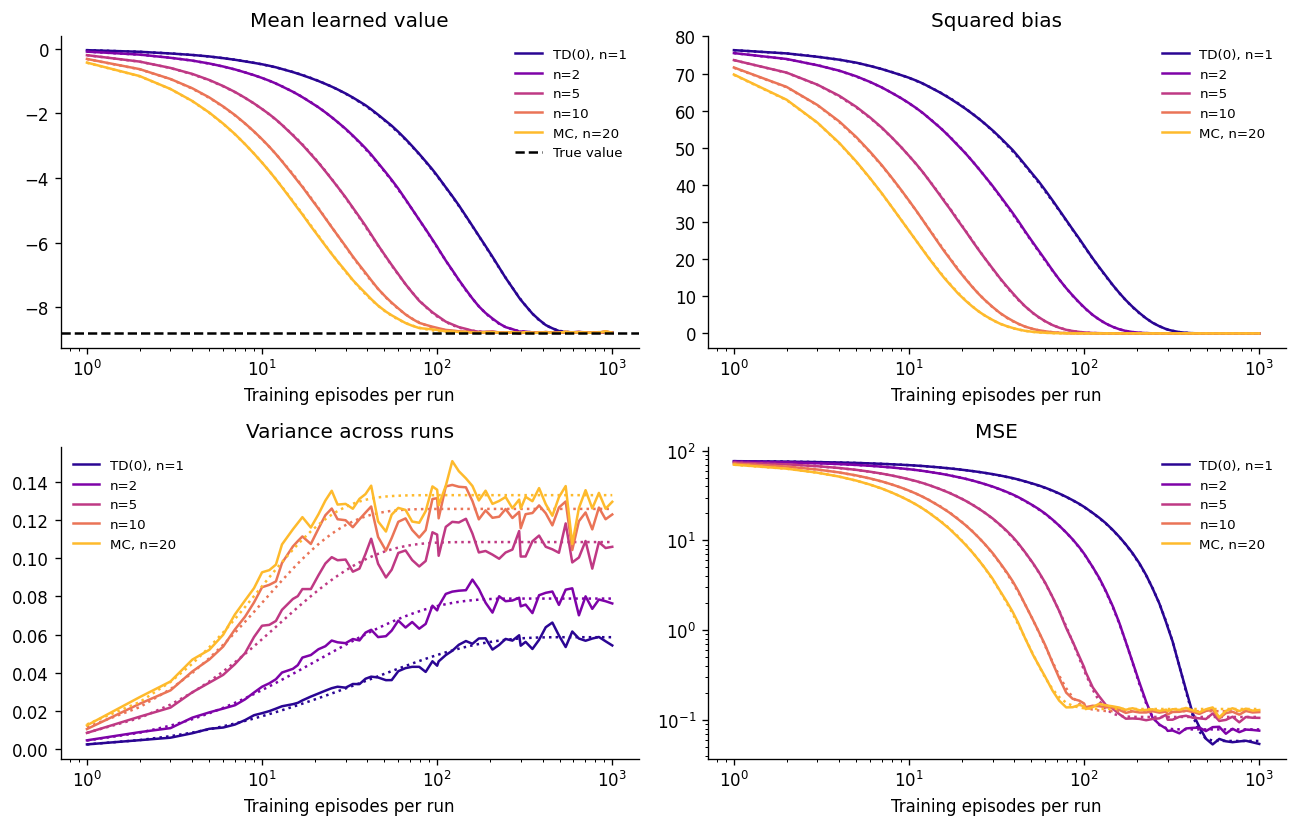

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
selected_n = (1, 2, 5, 10, 20)
for n, color in zip(selected_n, plt.cm.plasma(np.linspace(0.05, 0.85, len(selected_n)))):
    i = n-1
    label = "TD(0), n=1" if n == 1 else "MC, n=20" if n == 20 else f"n={n}"
    exact_bias = n_step_results["exact_mean"][:, i] - noise_truth
    observed = (n_step_results["mean"][:, i], n_step_results["bias"][:, i]**2,
                n_step_results["variance"][:, i], n_step_results["mse"][:, i])
    predicted = (n_step_results["exact_mean"][:, i], exact_bias**2,
                 n_step_results["exact_variance"][:, i], n_step_results["exact_mse"][:, i])
    for ax, y, exact in zip(axes.flat, observed, predicted):
        ax.plot(n_step_results["checkpoints"], y, color=color, label=label)
        ax.plot(n_step_results["checkpoints"], exact, color=color, linestyle=":")
axes[0, 0].axhline(noise_truth, color="black", linestyle="--", label="True value")
for ax, title in zip(axes.flat, ("Mean learned value", "Squared bias", "Variance across runs", "MSE")):
    ax.set(title=title, xlabel="Training episodes per run", xscale="log")
    ax.legend(frameon=False, fontsize=8)
axes[1, 1].set_yscale("log")
fig.tight_layout()

## What These Experiments Show

The source of MC variance depends on the environment. In Gridworld, returns vary because episode lengths vary. In the two-state task, episode length is fixed but state sequences and rewards vary. In the one-state task, independent reward noise alone is enough to produce the difference.

TD replaces part of a sampled return with an estimate. That can reduce variance, but errors in the estimate affect the target. Longer backups use less bootstrapping and more sampled rewards. Whether that improves MSE depends on how accurate the bootstrap values are and how much reward noise the longer target introduces.

Target statistics and learned-estimate statistics answer different questions. MC targets are unbiased for these on-policy finite-return objectives, but finite-training MC estimates can retain initialization bias. TD targets become unbiased if their bootstrap values are exact. Neither statement gives a universal ordering of the variances or MSEs of the trained methods.

All our comparisons used a constant learning rate of 0.05. That keeps the experiment controlled, but it is not a learning-rate search for either method. The observed variance plateaus reflect that constant step size. With different step sizes, initialization, horizons, or reward structure, the best backup length can change.

These toy environments let us inspect the mechanism directly. The n-step learning experiment also shows why an intermediate return can be useful: it can remove enough bias without paying the full variance cost of Monte Carlo at the available training budget.

## References

1. Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, second edition. MIT Press. Chapters 5–7 discuss Monte Carlo prediction, temporal-difference learning, and n-step bootstrapping. [Book website](https://incompleteideas.net/book/the-book-2nd.html).
2. Sutton, R. S., & Barto, A. G. *Chapter 6: Temporal Difference Learning*. [Author lecture slides](https://people.cs.umass.edu/~barto/courses/cs687/Chapter%206.pdf). The slides compare prediction targets and explain sampling and bootstrapping.

The experiments and exact moment calculations in this notebook are constructed examples, rather than reproductions of a numbered textbook figure.